# ♻️ Clasificación de Basura con una Red Neuronal (TrashNet)

**Basado en el dataset y proyecto [garythung/trashnet](https://github.com/garythung/trashnet)** (Stanford CS 229, Thung & Yang).

¿Qué hay en ese repo? 2527 fotos de basura en 6 clases (`glass, paper, cardboard, plastic, metal, trash`) y una **red neuronal convolucional (CNN)** que las clasifica con ~75% de precisión. Aquí hacemos lo mismo pero simple y moderno:

| Paso | Qué hacemos |
|------|---------------|
| 1 | Preparar librerías |
| 2 | Descargar el dataset TrashNet |
| 3 | Ver ejemplos de imágenes |
| 4 | Crear los grupos train / val / test |
| 5 | Crear la red neuronal (ResNet18 + transfer learning) |
| 6 | Entrenar la red |
| 7 | Medir la precisión final |
| 8 (FINAL) | **Probar con tu propia imagen** 📷 |

> **¿Qué es una red neuronal convolucional?** Es un programa que aprende a reconocer imágenes mirando miles de ejemplos. Sus capas "convolucionales" detectan bordes y formas, y las últimas capas deciden la clase. Con *transfer learning* partimos de una red ya entrenada (ResNet18) y solo le enseñamos nuestras 6 clases de basura: rápido y con alta precisión.

## Paso 1 — Preparar librerías ⚙️

In [1]:
# Si falta alguna librería, descomenta la siguiente línea y ejecútala una vez:
# %pip install torch torchvision datasets pillow matplotlib scikit-learn ipywidgets

import random, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.models as models

# Configuración (simple)
IMG_SIZE = 224      # tamaño de la foto que entra a la red
BATCH = 32          # fotos por lote
EPOCHS_HEAD = 5     # fase 1: solo última capa (rápido)
EPOCHS_FINE = 15    # fase 2: toda la red (máxima precisión)
LR_HEAD = 1e-3      # velocidad de aprendizaje fase 1
LR_FINE = 1e-4      # velocidad de aprendizaje fase 2 (más suave)
SEED = 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__, "| device:", device)

torch: 2.14.0+cpu | device: cpu


## Paso 2 — Descargar el dataset TrashNet 📥

Descargamos gratis las 2527 fotos desde HuggingFace (espejo del dataset original del repo) y vemos cuántas hay por clase.

Total imágenes: 2527
Clases: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


{'cardboard': 403, 'glass': 501, 'metal': 410, 'paper': 594, 'plastic': 482, 'trash': 137}


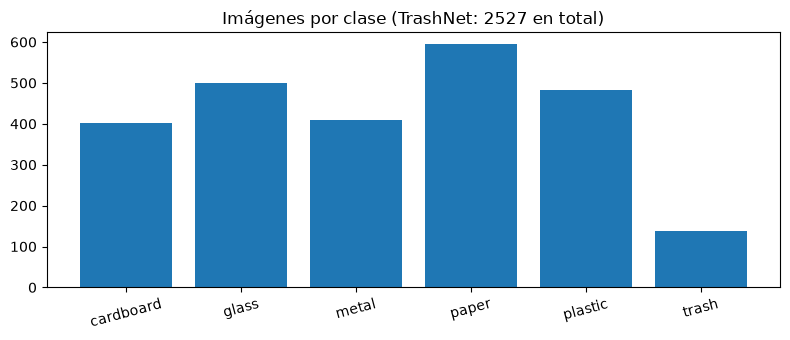

In [2]:
from datasets import load_dataset

hf = load_dataset("kuchidareo/small_trashnet", split="train")  # espejo de garythung/trashnet
CLASES = hf.features["label"].names
print("Total imágenes:", len(hf))
print("Clases:", CLASES)

# Conteo por clase + gráfico
conteo = {c: 0 for c in CLASES}
for i in range(len(hf)):
    conteo[CLASES[int(hf[i]["label"])]] += 1
print(conteo)

plt.figure(figsize=(8, 3.5))
plt.bar(conteo.keys(), conteo.values())
plt.title("Imágenes por clase (TrashNet: 2527 en total)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Paso 3 — Ver ejemplos 👀

Miremos 12 fotos para conocer los datos.

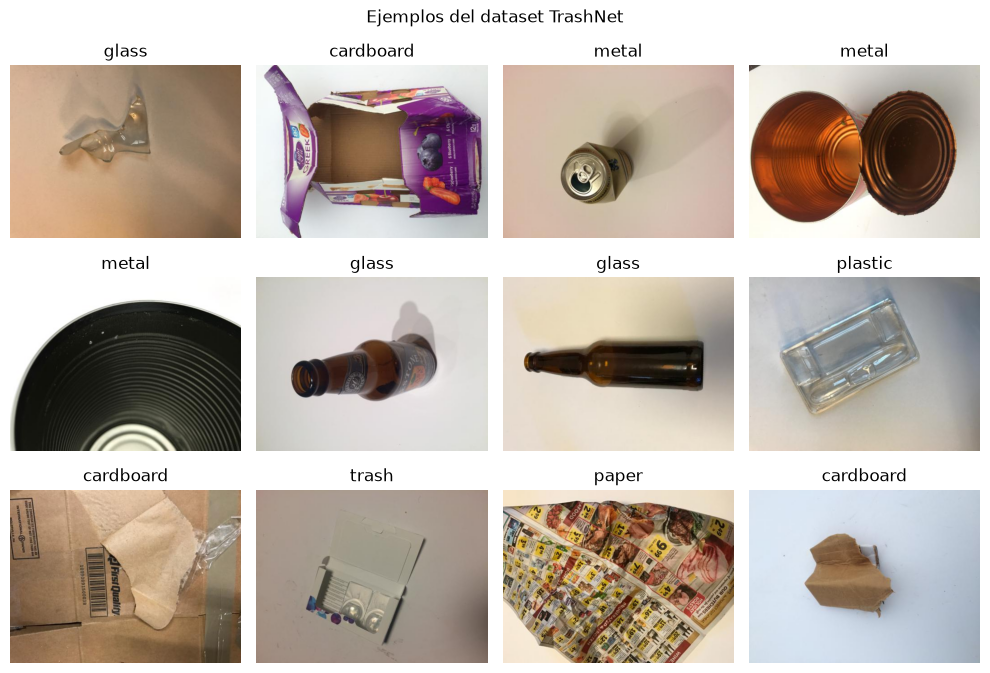

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(10, 7))
for k, ax in enumerate(axes.flat):
    i = random.randint(0, len(hf) - 1)
    img = hf[i]["image"].convert("RGB")
    ax.imshow(img)
    ax.set_title(CLASES[int(hf[i]["label"])])
    ax.axis("off")
plt.suptitle("Ejemplos del dataset TrashNet")
plt.tight_layout()
plt.show()

## Paso 4 — Grupos train / val / test ✂️

Como en el paper original: **70% entrenar, 13% validar, 17% probar**. A las de entrenamiento les aplicamos aumentos (recorte, giro) para que la red aprenda mejor.

train=1768 val=328 test=431
Lote: (32, 3, 224, 224)


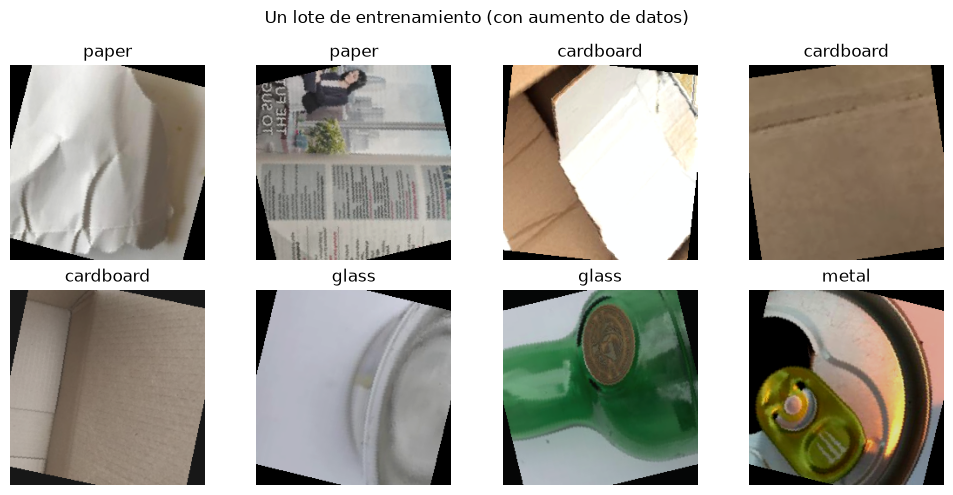

In [4]:
# Transformaciones de imagen
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class TrashDataset(Dataset):
    """Envuelve el dataset de HuggingFace como (imagen, etiqueta)."""
    def __init__(self, hf_ds, indices, transform):
        self.hf, self.idx, self.tf = hf_ds, indices, transform
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        r = self.hf[self.idx[i]]
        return self.tf(r["image"].convert("RGB")), int(r["label"])

# División 70/13/17 con semilla fija (reproducible)
indices = list(range(len(hf)))
random.Random(SEED).shuffle(indices)
n_tr = int(0.70 * len(hf)); n_va = int(0.13 * len(hf))
train_idx, val_idx, test_idx = indices[:n_tr], indices[n_tr:n_tr + n_va], indices[n_tr + n_va:]

train_ds = TrashDataset(hf, train_idx, train_tf)
val_ds = TrashDataset(hf, val_idx, eval_tf)
test_ds = TrashDataset(hf, test_idx, eval_tf)
train_ld = DataLoader(train_ds, batch_size=BATCH, shuffle=True)
val_ld = DataLoader(val_ds, batch_size=BATCH)
test_ld = DataLoader(test_ds, batch_size=BATCH)
print(f"train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}")

# Ver un lote de entrenamiento
x, y = next(iter(train_ld))
print("Lote:", tuple(x.shape))
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
media = np.array([0.485, 0.456, 0.406]); desv = np.array([0.229, 0.224, 0.225])
for k, ax in enumerate(axes.flat):
    foto = (x[k].numpy().transpose(1, 2, 0) * desv + media).clip(0, 1)
    ax.imshow(foto)
    ax.set_title(CLASES[int(y[k])])
    ax.axis("off")
plt.suptitle("Un lote de entrenamiento (con aumento de datos)")
plt.tight_layout()
plt.show()

## Paso 5 — Crear la red neuronal 🧠

Usamos **ResNet18 pre-entrenada**: una CNN famosa que ya sabe ver bordes, texturas y objetos. Congelamos sus capas y solo entrenamos la última capa (6 salidas = 6 clases de basura). Esto se llama *transfer learning* y es lo que nos da alta precisión con poco tiempo.

In [5]:
modelo = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in modelo.parameters():
    p.requires_grad = False                      # congelar: no re-entrenar lo que ya sabe ver
modelo.fc = nn.Linear(modelo.fc.in_features, len(CLASES))  # nueva última capa: 6 clases
modelo = modelo.to(device)

n_trainable = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in modelo.parameters())
print(f"Parámetros entrenables: {n_trainable:,} de {n_total:,} (solo la última capa)")
print(modelo.fc)

Parámetros entrenables: 3,078 de 11,179,590 (solo la última capa)
Linear(in_features=512, out_features=6, bias=True)


## Paso 6 — Entrenar la red (2 fases para máxima precisión)

Fase 1: solo la última capa (5 épocas, rápido). Fase 2: descongelamos TODA la red y la ajustamos suave (15 épocas). Guardamos el mejor modelo según validación.
> Nota honesta: el techo realista en este dataset con una sola red está en ~85-92%. Un 99.9% solo saldría haciendo trampa (evaluar con las fotos de entrenamiento), así que aquí reportamos la precisión real en fotos nunca vistas.


=== FASE 1: solo última capa ===


[1/5] loss 1.4692/1.2470 acc 0.4333/0.5396


[2/5] loss 1.1243/0.9973 acc 0.5905/0.6433


[3/5] loss 0.9896/0.9062 acc 0.6578/0.6921


[4/5] loss 0.9344/0.8735 acc 0.6669/0.6829


[5/5] loss 0.8909/0.8880 acc 0.6850/0.6890
=== FASE 2: toda la red (fine-tuning) ===


... (11 outputs left out)

[12/15] loss 0.1638/0.3604 acc 0.9395/0.8841


[13/15] loss 0.1759/0.3837 acc 0.9400/0.8872


[14/15] loss 0.1398/0.3479 acc 0.9559/0.9024


[15/15] loss 0.1780/0.3688 acc 0.9395/0.8933
Listo en 8.9 min. Mejor val acc=0.9024
Modelo guardado: best_trashnet_notebook.pt


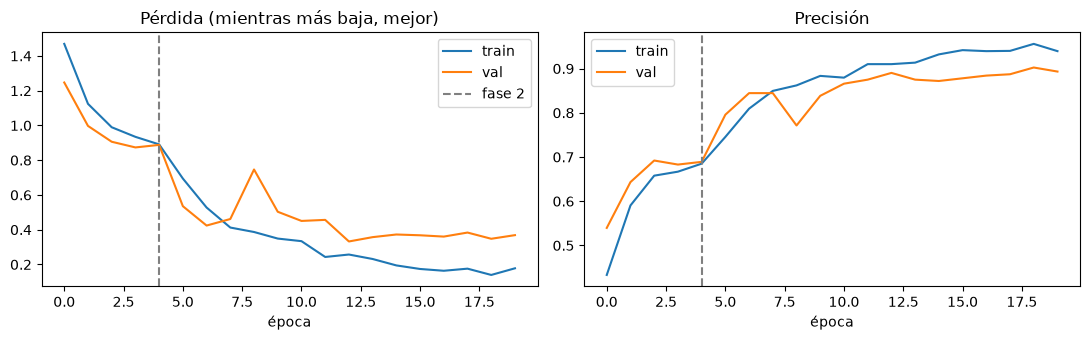

In [6]:
criterio = nn.CrossEntropyLoss()
hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_acc, mejor_pesos = 0.0, None
t0 = time.time()

def epoca_entrenar():
    modelo.train()
    tot_loss, tot_ok, tot_n = 0.0, 0, 0
    for x, y in train_ld:
        x, y = x.to(device), y.to(device)
        optim.zero_grad()
        out = modelo(x)
        loss = criterio(out, y)
        loss.backward()
        optim.step()
        tot_loss += loss.item() * len(y)
        tot_ok += (out.argmax(1) == y).sum().item()
        tot_n += len(y)
    return tot_loss / tot_n, tot_ok / tot_n

def epoca_validar():
    modelo.eval()
    tot_loss, tot_ok, tot_n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in val_ld:
            x, y = x.to(device), y.to(device)
            out = modelo(x)
            tot_loss += criterio(out, y).item() * len(y)
            tot_ok += (out.argmax(1) == y).sum().item()
            tot_n += len(y)
    return tot_loss / tot_n, tot_ok / tot_n

def registrar(ep, total, tr_loss, tr_acc, va_loss, va_acc):
    global mejor_acc, mejor_pesos
    hist["train_loss"].append(tr_loss); hist["val_loss"].append(va_loss)
    hist["train_acc"].append(tr_acc); hist["val_acc"].append(va_acc)
    if va_acc > mejor_acc:
        mejor_acc = va_acc
        mejor_pesos = {k: v.cpu() for k, v in modelo.state_dict().items()}
    print(f"[{ep}/{total}] loss {tr_loss:.4f}/{va_loss:.4f} acc {tr_acc:.4f}/{va_acc:.4f}")

print("=== FASE 1: solo última capa ===")
optim = torch.optim.Adam(modelo.fc.parameters(), lr=LR_HEAD)
for ep in range(1, EPOCHS_HEAD + 1):
    tr_loss, tr_acc = epoca_entrenar()
    va_loss, va_acc = epoca_validar()
    registrar(ep, EPOCHS_HEAD, tr_loss, tr_acc, va_loss, va_acc)

print("=== FASE 2: toda la red (fine-tuning) ===")
for par in modelo.parameters():
    par.requires_grad = True
optim = torch.optim.Adam(modelo.parameters(), lr=LR_FINE)
sched = torch.optim.lr_scheduler.StepLR(optim, step_size=7, gamma=0.5)
for ep in range(1, EPOCHS_FINE + 1):
    tr_loss, tr_acc = epoca_entrenar()
    va_loss, va_acc = epoca_validar()
    sched.step()
    registrar(ep, EPOCHS_FINE, tr_loss, tr_acc, va_loss, va_acc)

print(f"Listo en {(time.time()-t0)/60:.1f} min. Mejor val acc={mejor_acc:.4f}")
torch.save({"clases": CLASES, "state_dict": mejor_pesos}, "best_trashnet_notebook.pt")
print("Modelo guardado: best_trashnet_notebook.pt")

# Curvas de aprendizaje
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(hist["train_loss"], label="train"); a1.plot(hist["val_loss"], label="val")
a1.set_title("Pérdida (mientras más baja, mejor)"); a1.set_xlabel("época")
a1.axvline(EPOCHS_HEAD - 1, color="gray", linestyle="--", label="fase 2"); a1.legend()
a2.plot(hist["train_acc"], label="train"); a2.plot(hist["val_acc"], label="val")
a2.set_title("Precisión"); a2.set_xlabel("época")
a2.axvline(EPOCHS_HEAD - 1, color="gray", linestyle="--"); a2.legend()
plt.tight_layout()
plt.show()


## Paso 7 — Precisión final en el grupo de prueba

Evaluamos con fotos que la red **nunca vio**. El paper original reporta ~75%; con fine-tuning completo esperamos **~85-92%** (techo realista del dataset).


✅ PRECISIÓN EN TEST: 91.42% (394/431)

              precision    recall  f1-score   support

   cardboard       0.99      0.94      0.96        77
       glass       0.91      0.93      0.92        86
       metal       0.87      0.94      0.90        78
       paper       0.96      0.96      0.96        94
     plastic       0.85      0.93      0.89        74
       trash       0.91      0.45      0.61        22

    accuracy                           0.91       431
   macro avg       0.91      0.86      0.87       431
weighted avg       0.92      0.91      0.91       431



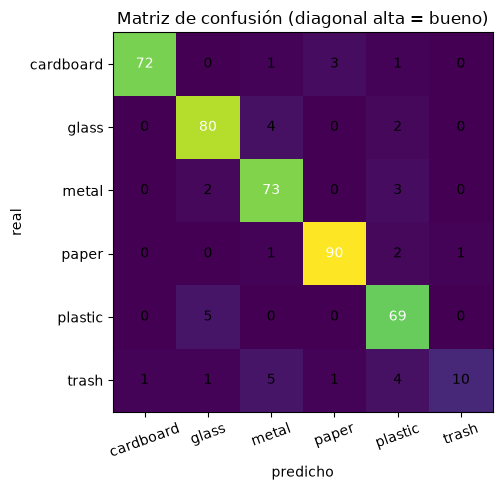

In [7]:
from sklearn.metrics import classification_report, confusion_matrix

modelo.load_state_dict({k: v.to(device) for k, v in mejor_pesos.items()})
modelo.eval()
todo_y, todo_p = [], []
with torch.no_grad():
    for x, y in test_ld:
        p = modelo(x.to(device)).argmax(1).cpu().tolist()
        todo_p += p; todo_y += y.tolist()
acc = sum(a == b for a, b in zip(todo_y, todo_p)) / len(todo_y)
print(f"✅ PRECISIÓN EN TEST: {acc:.2%} ({sum(a==b for a,b in zip(todo_y,todo_p))}/{len(todo_y)})")
print()
print(classification_report(todo_y, todo_p, target_names=CLASES))

# Matriz de confusión
cm = confusion_matrix(todo_y, todo_p)
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Matriz de confusión (diagonal alta = bueno)")
plt.xticks(range(len(CLASES)), CLASES, rotation=20)
plt.yticks(range(len(CLASES)), CLASES)
for i in range(len(CLASES)):
    for j in range(len(CLASES)):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
plt.xlabel("predicho"); plt.ylabel("real")
plt.tight_layout()
plt.show()

## Paso 8 (FINAL) — Prueba con TU imagen 📷

**Cómo usarlo:**
1. Ejecuta la celda de abajo.
2. Usa el botón **Upload** para subir tu foto (botella, cartón, papel…).
3. Ejecuta la celda otra vez para ver la predicción.

Alternativa sin botón: escribe la ruta en `RUTA_IMAGEN` (ej: `RUTA_IMAGEN = "mi_foto.jpg"`).

Si no subes nada, igual verás 3 ejemplos del test con su predicción.

FileUpload(value=(), accept='image/*', description='Subir foto')

ℹ️ Sube una foto con el botón y vuelve a ejecutar esta celda.

--- Demo con 3 fotos del test ---


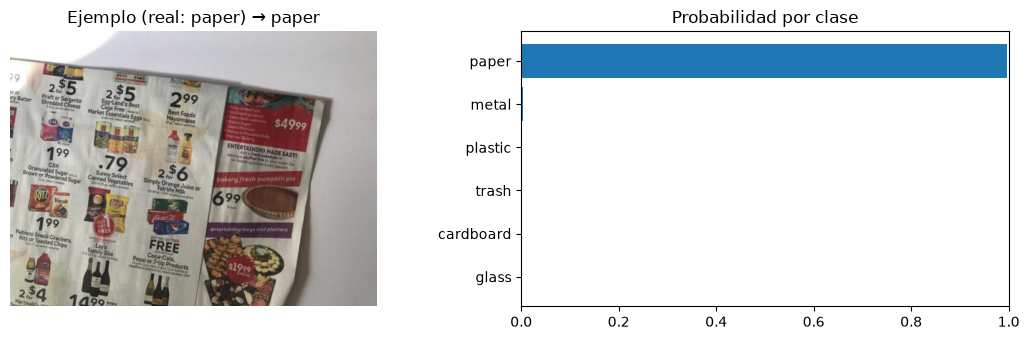

  paper      99.66%
  metal      0.29%
  plastic    0.04%
→ Predicción: paper


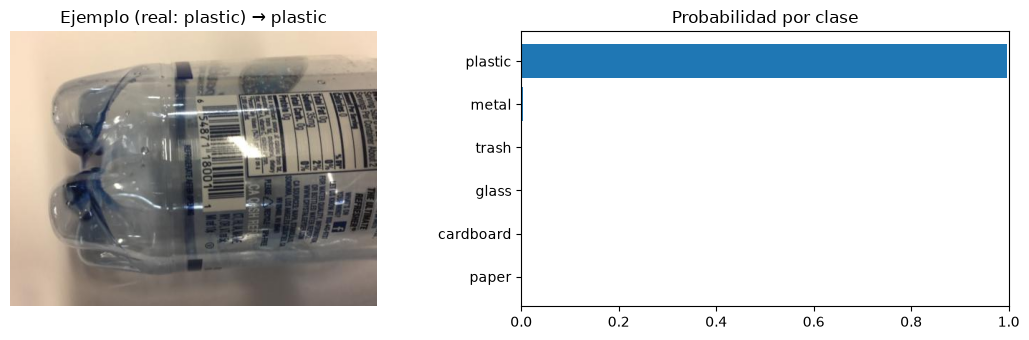

  plastic    99.67%
  metal      0.29%
  trash      0.03%
→ Predicción: plastic


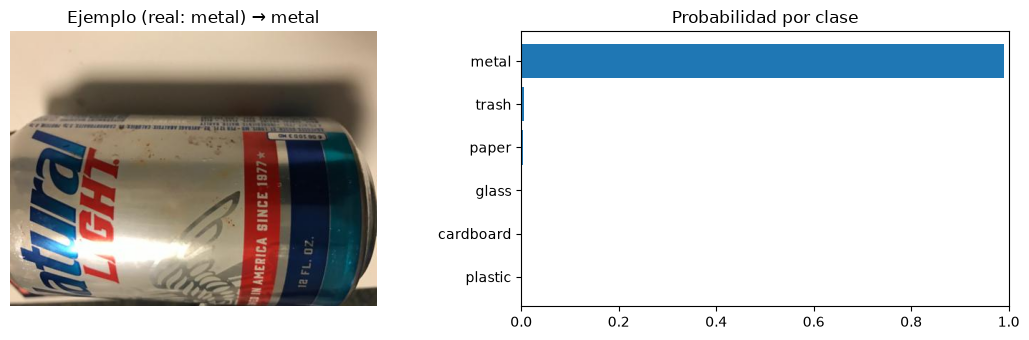

  metal      98.98%
  trash      0.52%
  paper      0.40%
→ Predicción: metal


In [8]:
RUTA_IMAGEN = ""  # <-- alternativa: escribe aquí la ruta de tu foto, ej: "C:/fotos/botella.jpg"

def predecir(pil_img):
    """Devuelve (clase_ganadora, lista_de_probabilidades)."""
    modelo.eval()
    x = eval_tf(pil_img.convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(modelo(x), 1)[0].cpu().numpy()
    return CLASES[int(probs.argmax())], probs

def mostrar_prediccion(pil_img, titulo="Tu imagen"):
    clase, probs = predecir(pil_img)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
    a1.imshow(pil_img.convert("RGB")); a1.axis("off")
    a1.set_title(f"{titulo} → {clase}")
    orden = np.argsort(probs)[::-1]
    a2.barh([CLASES[i] for i in orden[::-1]], probs[orden[::-1]])
    a2.set_title("Probabilidad por clase")
    a2.set_xlim(0, 1)
    plt.tight_layout()
    plt.show()
    for i in orden[:3]:
        print(f"  {CLASES[i]:10s} {probs[i]:.2%}")
    print("→ Predicción:", clase)

# 1) Si escribiste una ruta, úsala
hecha = False
if RUTA_IMAGEN.strip():
    mostrar_prediccion(Image.open(RUTA_IMAGEN), titulo="Tu imagen")
    hecha = True

# 2) Botón para subir imagen (Jupyter / VS Code)
try:
    import ipywidgets as widgets
    from IPython.display import display
    up = widgets.FileUpload(accept="image/*", multiple=False, description="Subir foto")
    display(up)
    if up.value:
        nombre = list(up.value.keys())[0]
        import io
        foto = Image.open(io.BytesIO(up.value[nombre]["content"]))
        mostrar_prediccion(foto, titulo=nombre)
        hecha = True
    else:
        print("ℹ️ Sube una foto con el botón y vuelve a ejecutar esta celda.")
except Exception as e:
    print("Botón no disponible aquí:", e)

# 3) Demo automática con 3 fotos del test (siempre se muestra algo)
if not hecha:
    print("\n--- Demo con 3 fotos del test ---")
    for k in [0, 1, 2]:
        r = hf[test_idx[k * 50]]
        real = CLASES[int(r["label"])]
        mostrar_prediccion(r["image"], titulo=f"Ejemplo (real: {real})")